In [1]:
import numpy as np
import cv2 as cv
from matplotlib import pyplot as plt

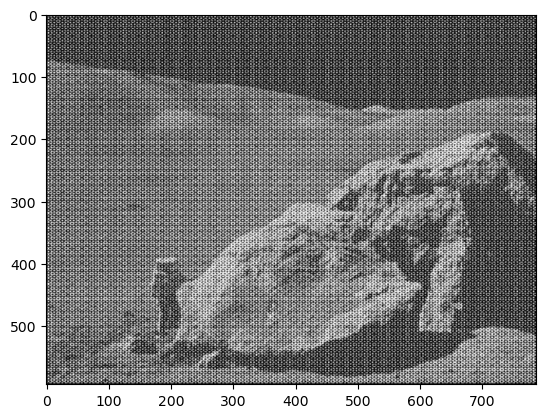

In [3]:
img = cv.imread('periodic_noise.jpg', cv.IMREAD_GRAYSCALE)
plt.imshow(img, cmap='gray')

# Высокочастотная фильтрация на основе ядра Гаусса

In [6]:
dft = cv.dft(np.float32(img),flags = cv.DFT_COMPLEX_OUTPUT)
dft_shift = np.fft.fftshift(dft)

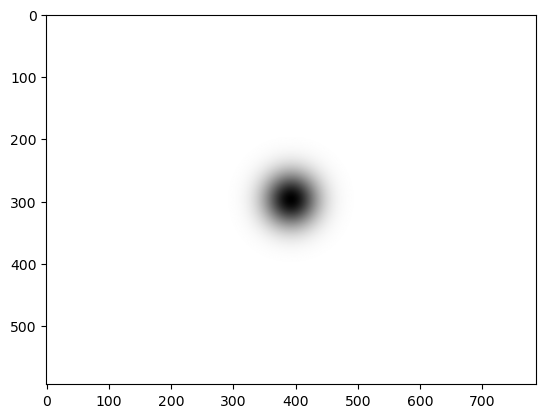

In [7]:
h, w = img.shape
centerX, centerY = (int(h/2), int(w/2))

sigma = 30
y, x = np.ogrid[:h, :w]
D2 = (y - centerX)**2 + (x - centerY)**2

gauss_lp = np.exp(-D2 / (2*sigma**2))
gauss_hp = 1 - gauss_lp 

plt.imshow(gauss_hp, cmap='gray')

In [11]:
mask = np.zeros((h, w, 2), np.float32)
mask[:,:,0] = gauss_hp
mask[:,:,1] = gauss_hp 

dft_shift_hp = dft_shift * mask

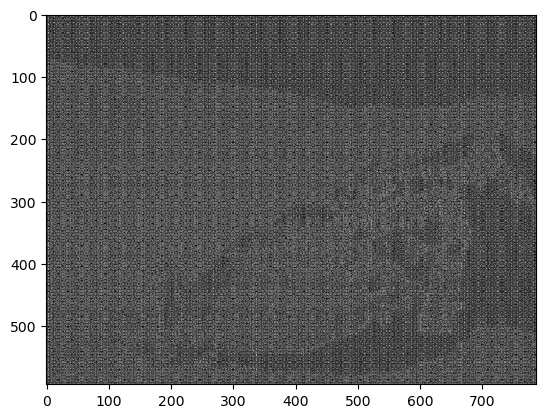

In [12]:
f_ishift = np.fft.ifftshift(dft_shift_hp)

img_back = cv.idft(f_ishift)
img_back = cv.magnitude(img_back[:,:,0], img_back[:,:,1])

plt.imshow(img_back, cmap='gray')

# Свёртка через преобразование Фурье

In [13]:
ksize = 15
kernel = np.ones((ksize, ksize), np.float32) / (ksize*ksize)

kernel_padded = np.zeros((h, w), np.float32)
kernel_padded[:ksize, :ksize] = kernel
kernel_padded = np.roll(kernel_padded, -(ksize//2), axis=0)
kernel_padded = np.roll(kernel_padded, -(ksize//2), axis=1)

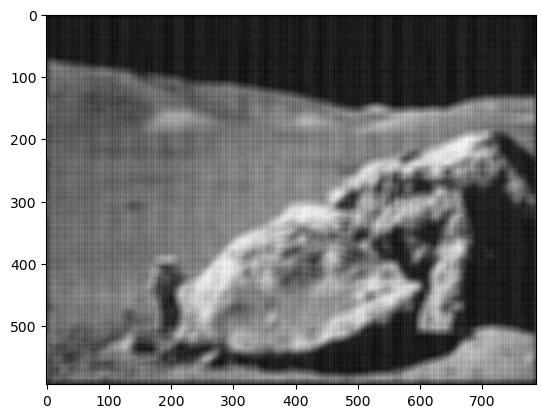

In [14]:
dft_img = cv.dft(np.float32(img), flags=cv.DFT_COMPLEX_OUTPUT)
dft_kernel = cv.dft(kernel_padded, flags=cv.DFT_COMPLEX_OUTPUT)
dft_product = cv.mulSpectrums(dft_img, dft_kernel, 0) 

conv_result = cv.idft(dft_product, flags=cv.DFT_SCALE | cv.DFT_REAL_OUTPUT)
plt.imshow(conv_result, cmap='gray')

# Удаление периодического шума

In [25]:
mag = cv.magnitude(dft_shift[:,:,0], dft_shift[:,:,1])

mag_search = mag.copy()
dist = np.sqrt((y - centerX)**2 + (x - centerY)**2)
mag_search[dist < 20] = 0

dilated = cv.dilate(mag_search, np.ones((9,9), np.uint8))
local_max_mask = (mag_search == dilated)
threshold = np.percentile(mag_search[mag_search > 0], 99.9)
peaks = np.argwhere(local_max_mask & (mag_search > threshold))
print("Найдено пиков шума:", len(peaks))

Найдено пиков шума: 148


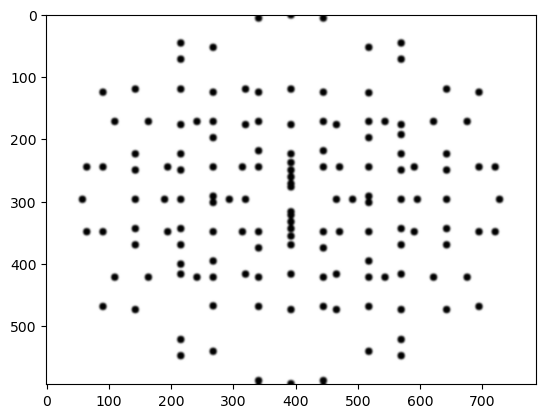

In [26]:
mask2d = np.ones((h, w), np.float32)           
for (py, px) in peaks:
    cv.circle(mask2d, (int(px), int(py)), 6, 0, -1)

mask2d = cv.GaussianBlur(mask2d, (7, 7), 0) 

mask = np.zeros((h, w, 2), np.float32)
mask[:,:,0] = mask2d
mask[:,:,1] = mask2d
plt.imshow(mask2d, cmap='gray')

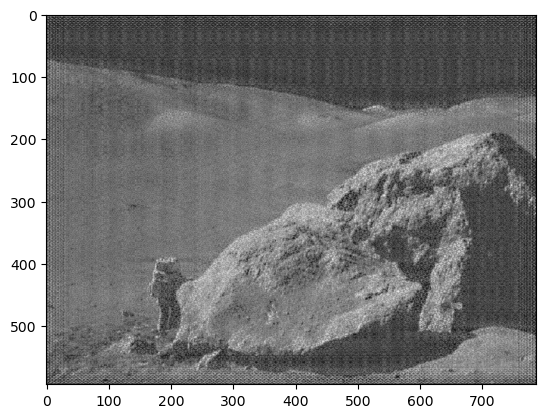

In [27]:
dft_shift_notch = dft_shift * mask
f_ishift = np.fft.ifftshift(dft_shift_notch)
img_back = cv.idft(f_ishift, flags=cv.DFT_SCALE)
img_back = cv.magnitude(img_back[:,:,0], img_back[:,:,1])

plt.imshow(img_back, cmap='gray')